# 01 · Preprocessing — Gulati 2020 Breast (malignant compartment)

Isolate malignant cells, threshold thin samples, integrate patients (Harmony), embed,
remove detached islands, resolve the manifold's transcriptional structure, and record a
consistent house orientation. Gulati et al. profiled breast tumours by **SmartSeq2**, so
expression is **TPM** (the loader passes TPM through and `log1p`s it). The malignant manifold
is a single low-cycling body carrying one continuous embryonic axis (resolved in 02–04).
Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)        # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)  # h5ads
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Gulati2020_Breast | category: Breast


### Load malignant compartment
Gulati et al. supply a per-cell `cell_type` annotation; **Malignant** is an explicit label
(the publication's malignancy call). The loader exposes it as `celltype`. Select it and confirm
the expression scale (log1p of TPM).

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of SmartSeq2 TPM)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Gulati2020_Breast
Done.
full atlas: (1902, 42132)
malignant: (861, 42132) | samples: 8
expression: X max 12.42 (log1p of SmartSeq2 TPM)


### Cell-cycle scoring (Regev–Tirosh programmes)
Score the S and G2/M programmes so the trajectory can be checked against proliferation later.
`phase` -> `cell_cycle_phase`; `cycling` = S or G2/M.

In [4]:
s_genes = ('MCM5 PCNA TYMS FEN1 MCM2 MCM4 RRM1 UNG GINS2 MCM6 CDCA7 DTL PRIM1 UHRF1 HELLS RFC2 '
    'RPA2 NASP RAD51AP1 GMNN WDR76 SLBP CCNE2 UBR7 POLD3 MSH2 ATAD2 RAD51 RRM2 CDC45 CDC6 EXO1 TIPIN '
    'DSCC1 BLM CASP8AP2 USP1 CLSPN POLA1 CHAF1B BRIP1 E2F8').split()
g2m_genes = ('HMGB2 CDK1 NUSAP1 UBE2C BIRC5 TPX2 TOP2A NDC80 CKS2 NUF2 CKS1B MKI67 TMPO CENPF TACC3 '
    'FAM64A SMC4 CCNB2 CKAP2L CKAP2 AURKB BUB1 KIF11 ANP32E TUBB4B GTSE1 KIF20B HJURP CDCA3 HN1 CDC20 '
    'TTK CDC25C KIF2C RANGAP1 NCAPD2 DLGAP5 CDCA2 CDCA8 ECT2 KIF23 HMMR AURKA PSRC1 ANLN LBR CKAP5 '
    'CENPE CTCF NEK2 G2E3 GAS2L3 CBX5 CENPA').split()
sg = [g for g in s_genes if g in adata.var_names]; gg = [g for g in g2m_genes if g in adata.var_names]
sc.tl.score_genes_cell_cycle(adata, s_genes=sg, g2m_genes=gg)
adata.obs['cell_cycle_phase'] = adata.obs['phase'].astype(str)
adata.obs['cycling'] = adata.obs['phase'].isin(['S','G2M'])
print('cell-cycle phase:', adata.obs['cell_cycle_phase'].value_counts().to_dict())
print('cycling fraction: %.3f' % adata.obs['cycling'].mean())

cell-cycle phase: {'G2M': 307, 'S': 307, 'G1': 247}
cycling fraction: 0.713


### Sample thresholding — multiplicative gap-finding, with a floor fallback
Look for the largest **multiplicative** cliff in the sorted per-sample counts (the natural
separatrix between tumour-bearing and spillover samples). If a *dominant* cliff exists, cut at its
geometric mean; otherwise fall back to a >=100-cell floor so Harmony has enough cells per patient.
Gulati's counts are smooth (`43,68,80,83,107,139,150,191`) with no dominant cliff — the largest gap
(68->43, ratio 1.58) is within noise of its runner-up — so the **floor >=100** applies.

In [5]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
srt = np.sort(ratios)[::-1]; top, second = srt[0], srt[1]
FLOOR = 100
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*FLOOR)
print('sorted per-sample counts:', dict(zip(n.index, n.values.astype(int))))
print('gap ratios:', [f'{int(vals[i])}->{int(vals[i+1])}:{ratios[i]:.2f}' for i in range(len(ratios))])
print(f'argmax gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {top:.2f}); top/second = {top/second:.2f}; dominant cliff = {dominant}')
if dominant:
    thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
    print(f'dominant spillover cliff -> geometric-mean threshold = {thresh}')
else:
    thresh = FLOOR
    print(f'no dominant cliff (top gap ~ runner-up) -> floor >= {FLOOR}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n[n>=thresh].min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: {'SU20_T': np.int64(191), 'SU21_T': np.int64(150), 'SU9_T': np.int64(139), 'SU17_T': np.int64(107), 'COH69_T': np.int64(83), 'SU2_T': np.int64(80), 'SU4_T': np.int64(68), 'SU58_T': np.int64(43)}
gap ratios: ['191->150:1.27', '150->139:1.08', '139->107:1.30', '107->83:1.29', '83->80:1.04', '80->68:1.18', '68->43:1.58']
argmax gap 68->43 (ratio 1.58); top/second = 1.22; dominant cliff = False
no dominant cliff (top gap ~ runner-up) -> floor >= 100
kept 4/8 samples (min per-sample = 107) -> 587 cells


### Overdispersion, PCA, Harmony integration, embedding
`theta` is selected by a same-sample-neighbour-fraction sweep (lower = better mixing). Mixing
improves from theta=2 to theta=5 and then flattens (theta=10 within noise of theta=5), and the
fully-mixed expectation for these four samples is ~0.26, so **theta=5** is chosen — enough to
remove the patient batch without over-integrating.

In [6]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

from sklearn.neighbors import NearestNeighbors as _NN
def _same_sample_frac(rep):
    idx = _NN(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([ (s[idx[i]]==s[i]).mean() for i in range(len(s)) ]))
p = adata.obs['sample'].value_counts(normalize=True).values
print('fully-mixed expectation (sum p^2) = %.3f' % (p**2).sum())
base = _same_sample_frac(adata.obsm['X_pca'][:,:20])
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:20])
print('same-sample neighbour fraction | pre-Harmony %.3f' % base, '| sweep', {k: round(v,3) for k,v in sweep.items()})
theta = 5
print('selected theta =', theta, '(mixing flattens by theta=5; theta=10 within noise)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 98 over-dispersed features (0:00:00) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 98
fully-mixed expectation (sum p^2) = 0.260
2026-08-05 00:41:35,465 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-05 00:41:35,536 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-05 00:41:35,537 - harmonypy - INFO - Iteration 1 of 30
2026-08-05 00:41:35,600 - harmonypy - INFO - Iteration 2 of 30
2026-08-05 00:41:35,657 - harmonypy - INFO - Iteration 3 of 30
2026-08-05 00:41:35,699 - harmonypy - INFO - Iteration 4 of 30
2026-08-05 00:41:35,735 - harmonypy - INFO - Iteration 5 of 30
2026-08-05 00:41:35,762 - harmonypy - INFO - Iteration 6 of 30
2026-08-05 00:41:35,78

### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and drop any cell
outside the main connected component — stripping physically detached specks while keeping the
continuous axis. Gulati's manifold is a single connected component (nothing removed).

In [7]:
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

removed 0 cells in 0 detached islands


### Compartment split + labelling (data-driven, marker-based)
Low-resolution Leiden (res=0.15) recovers the manifold's lobes; check each lobe's cycling
fraction and proliferation score. Despite a moderate global cycling fraction (SmartSeq2 depth),
no lobe is a distinct proliferative spike, so the manifold is one **low-cycling Body** with no
proliferative compartment to scope out of the trajectory.

In [8]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('overall cycling fraction: %.3f' % adata.obs['cycling'].mean())
print('cycling fraction per lobe:', adata.obs.groupby('lobe', observed=True)['cycling'].mean().round(3).to_dict())
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
print('proliferation score per lobe:',
      adata.obs.groupby('lobe', observed=True)['prolif_score'].mean().round(3).to_dict())
adata.obs['compartment'] = 'Body'
adata.obs['compartment'] = adata.obs['compartment'].astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

lobe sizes: {'0': 423, '1': 164}
overall cycling fraction: 0.698
cycling fraction per lobe: {'0': 0.671, '1': 0.768}
proliferation score per lobe: {'0': -0.623, '1': -0.654}
compartments: {'Body': 587}


### House orientation — one consistent layout for every UMAP
The developmental axis is **diagonal** in the raw joint embedding, so all trajectory panels are
shown after a single **rigid rotation** (distances preserved) that puts the axis of maximal
variance horizontal, with the Gast/pSom-high (Crest-low) developmental origin on the left. Stored
as `X_umap_lin` and re-used unchanged by 02–04.

In [9]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
origin_score = (S[:,0] + S[:,1]) - S[:,2]     # Gast+pSom-high / Crest-low = developmental origin
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)          # vt[0] = axis of maximal variance
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[ np.cos(-theta_rot), -np.sin(-theta_rot)],
               [ np.sin(-theta_rot),  np.cos(-theta_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()                     # origin pole -> left (negative x)
if np.average(xyr[:,0], weights=w) > 0:
    xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(theta_rot):+.1f}deg (distances preserved), '
      f'Gast/pSom-high origin pole on left; stored as X_umap_lin')

manifold aspect (max/min std): 1.15
house orientation: rigid rotation -38.6deg (distances preserved), Gast/pSom-high origin pole on left; stored as X_umap_lin


### Gate 1 — batch mixing & manifold continuity
Judged on the regenerated embedding plus a per-neighbourhood metric (iLISI), not a single scalar.
Samples must intermix (no per-patient islands) on one continuous manifold.

In [10]:
n_samp = adata.obs['sample'].nunique()
def _ilisi(rep, labels, k=90):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep)
    idx = nn.kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]
    out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
il_pre = np.median(_ilisi(adata.obsm['X_pca'][:,:20], adata.obs['sample'].values))
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta=5) {il_post:.2f} of {n_samp} samples')
print(f'{n_samp} samples share one continuous manifold (one connected component, no islands removed).')
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold -> PASS')

iLISI median: pre-Harmony 2.77 -> post-Harmony(theta=5) 3.56 of 4 samples
4 samples share one continuous manifold (one connected component, no islands removed).
Gate 1: samples intermix per-neighbourhood on one continuous manifold -> PASS


### Visual check — sample / phase / compartment on the embedding

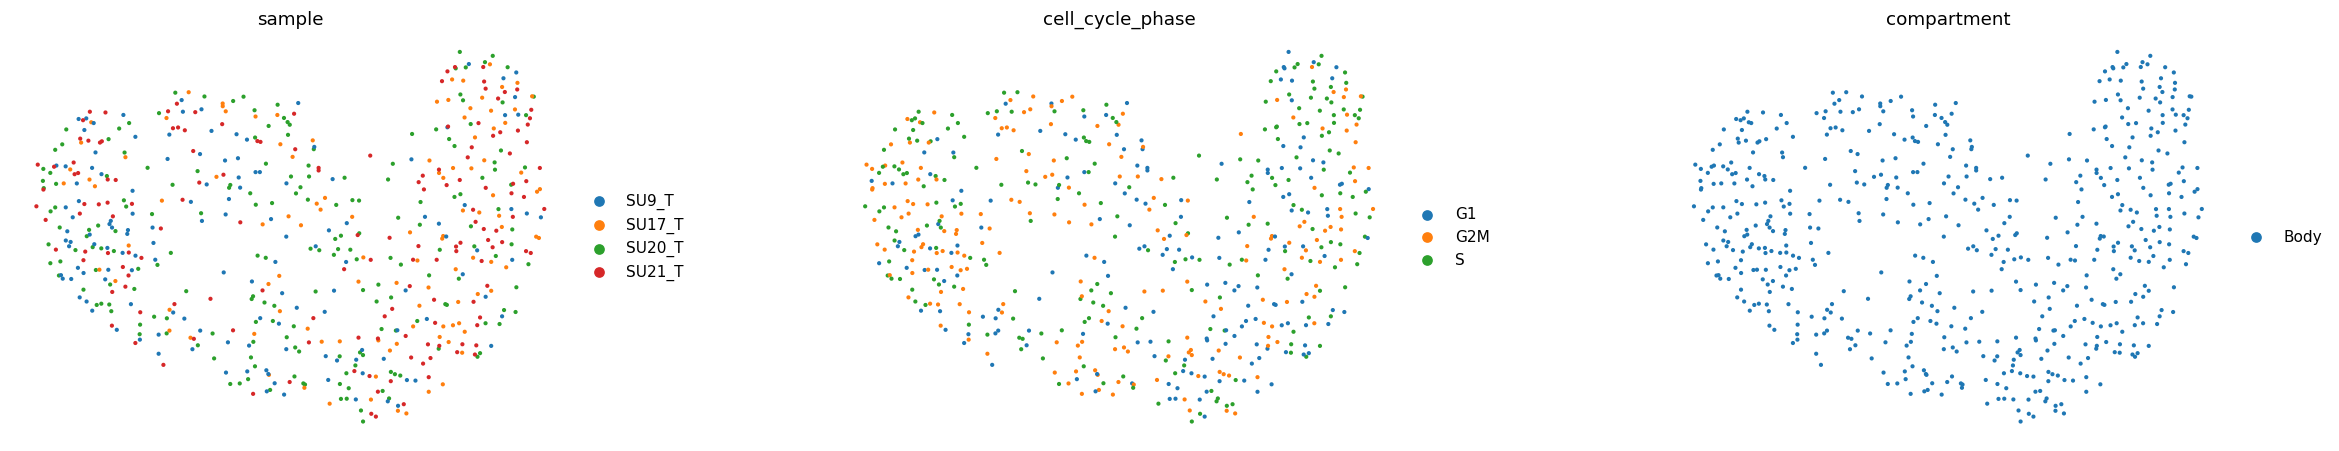

In [11]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
sc.pl.umap(plot, color=['sample','cell_cycle_phase','compartment'], size=30, wspace=.35, frameon=False)

### Save processed data
Coerce mixed-type object metadata to numeric-or-string so the manifold is h5ad-serializable;
analysis-relevant columns are preserved.

In [12]:
protect = {'sample','compartment','lobe','celltype','cell_type','cell_cycle_phase','phase','source','patient','cell_subtype'}
for c in adata.obs.columns:
    if c in protect:
        adata.obs[c] = adata.obs[c].astype(str).astype('category'); continue
    col = adata.obs[c]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum() > 0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[c] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (587, 26582)


### Sample-integration figure (deliverable)

saved samples.pdf | cells: 587


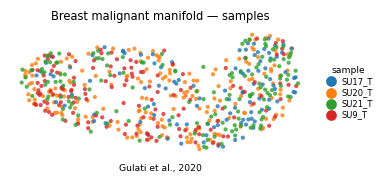

In [13]:
# House style figsize=(3.5,1.5) horizontal strip, size=30. Colour = sample: intermixing
# across the strip is the Gate-1 batch-integration evidence, on the house orientation (X_umap_lin).
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Breast malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Gulati et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])